# B1 — Baseline battery

Fixed orderings of the test CVEs (published ≥ 2023-01-01), scored against KEV with the locked `evaluate()`. Ties are broken at random per seed, 10 seeds, mean ± std. `epss_current` is a **leaky reference**, not a competitor (A6). See `src/models/baselines.py` for the full rationale.

In [1]:
import os
import sys
from pathlib import Path

# Every src/ path is relative to the project root (data/..., outputs/...).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.models.baselines import run

In [2]:
out = run()
print(f"test CVEs: {len(out['test']):,}  KEV: {int(out['y_test'].sum())}  CVSS v4 coverage: {out['v4_coverage']:.1%}")
out["summary"]

2026/11/24 11:27:24 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/spopa/Documents/Internship Project/internship-project/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


test CVEs: 227,026  KEV: 752  CVSS v4 coverage: 21.4%


,pr_auc,precision_at_10,precision_at_50,precision_at_100,recall_at_100,ndcg_at_100,mrr,roc_auc
baseline,,,,,,,,
epss_current,0.413 ± 0.0,1.0 ± 0.0,0.98 ± 0.0,0.86 ± 0.0,0.1144 ± 0.0,0.892 ± 0.0,1.0 ± 0.0,0.9785 ± 0.0
cvss_v3,0.0148 ± 0.0007,0.04 ± 0.0516,0.034 ± 0.0232,0.037 ± 0.0149,0.0049 ± 0.002,0.0412 ± 0.0235,0.2249 ± 0.3133,0.7861 ± 0.0004
severity_label,0.0104 ± 0.0004,0.01 ± 0.0316,0.014 ± 0.0165,0.016 ± 0.0107,0.0021 ± 0.0014,0.0169 ± 0.0126,0.0851 ± 0.1489,0.7634 ± 0.0035
cvss_v4,0.0056 ± 0.0002,0.02 ± 0.0422,0.026 ± 0.019,0.028 ± 0.0079,0.0037 ± 0.001,0.0261 ± 0.0091,0.0674 ± 0.0714,0.4803 ± 0.0093
random,0.0034 ± 0.0002,0.01 ± 0.0316,0.002 ± 0.0063,0.002 ± 0.0042,0.0003 ± 0.0006,0.0038 ± 0.0096,0.0545 ± 0.1566,0.5017 ± 0.0101
recency,0.0025 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0005 ± 0.0,0.3934 ± 0.0


## CVSS v3 vs v4 on equal footing
Only the CVEs that carry a v4 score (almost all CNA-supplied, not NVD).

In [3]:
out["subset_summary"]

,pr_auc,precision_at_10,precision_at_50,precision_at_100,recall_at_100,ndcg_at_100,mrr,roc_auc
baseline,,,,,,,,
cvss_v4,0.0189 ± 0.0009,0.03 ± 0.0483,0.024 ± 0.0158,0.026 ± 0.0117,0.022 ± 0.0099,0.0239 ± 0.0101,0.0566 ± 0.043,0.8591 ± 0.0011
cvss_v3,0.0171 ± 0.0011,0.03 ± 0.0675,0.02 ± 0.0231,0.024 ± 0.0143,0.0203 ± 0.0121,0.023 ± 0.0156,0.0583 ± 0.0512,0.8618 ± 0.0015
random,0.0026 ± 0.0002,0.0 ± 0.0,0.002 ± 0.0063,0.002 ± 0.0042,0.0017 ± 0.0036,0.0017 ± 0.0037,0.0066 ± 0.0097,0.5111 ± 0.0228


## EPSS-current calibration (the only probabilistic baseline)

In [4]:
out["calibration"]

{'epss_current_brier': 0.0038312789160193403,
 'epss_current_ece': 0.007488440081844324,
 'epss_current_coverage': 0.9665897298106825}

## Why recency scores below random: KEV lag

In [5]:
import pandas as pd
t = out["test"].assign(kev=out["y_test"].values,
                       year=pd.to_datetime(out["test"]["published_date"], format="ISO8601", utc=True).dt.year)
t.groupby("year").kev.agg(cves="size", kev="sum", kev_rate="mean").round(5)

,cves,kev,kev_rate
year,,,
2023,30949,166,0.00536
2024,40704,161,0.00396
2025,49972,199,0.00398
2026,105401,226,0.00214


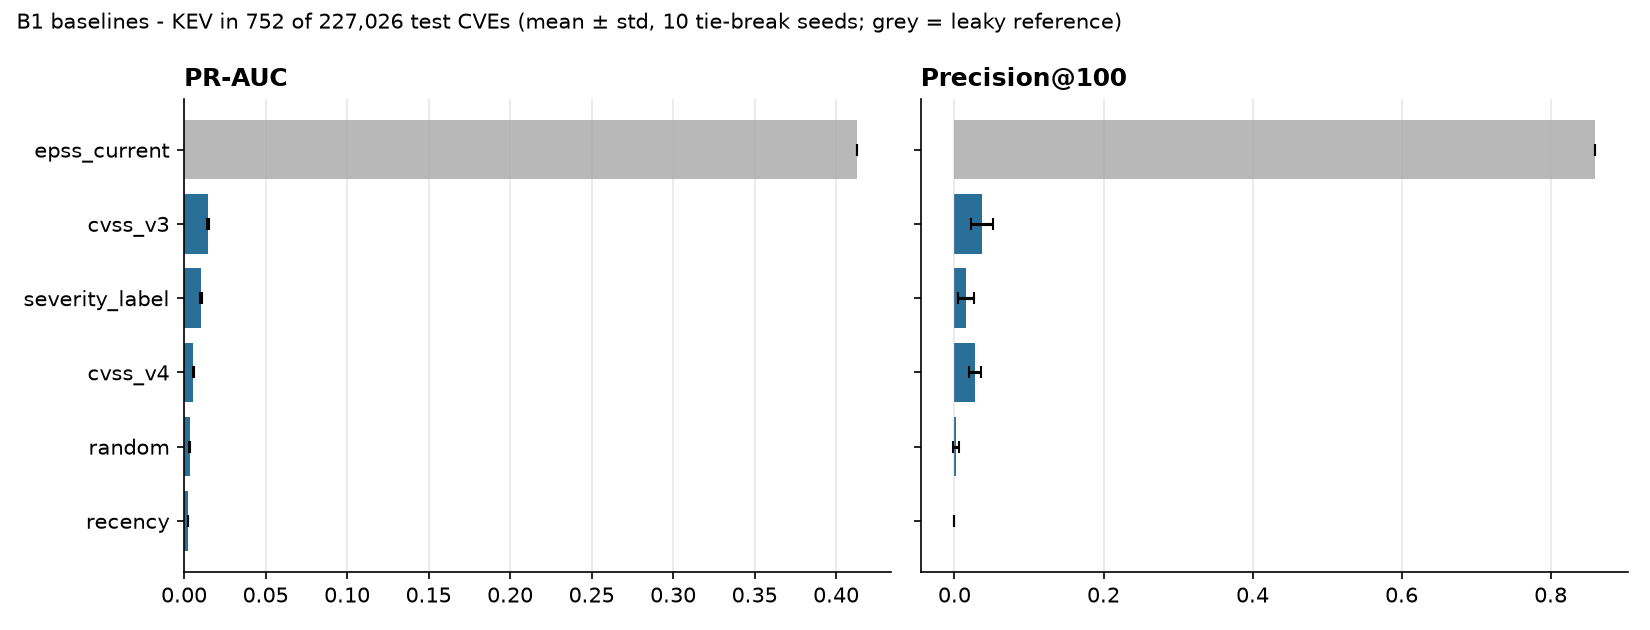

In [6]:
from IPython.display import Image
Image("outputs/b1_baselines.png")